In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import colorsys

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [4]:
# Load the dataset (update the path/filename as needed)
df = pd.read_csv('data/student_habits_performance.csv')
display(df.head())

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [7]:
# Create a binary classification target from exam_score (1 = Pass >= 70, 0 = Fail < 70)
df['passed'] = df['exam_score'].apply(lambda x: 1 if x >= 70.0 else 0)

# Encode binary categorical features (0 or 1)
df['part_time_job_num'] = df['part_time_job'].map({'No': 0, 'Yes': 1})
df['extracurricular_num'] = df['extracurricular_participation'].map({'No': 0, 'Yes': 1})

# Encode ordered categorical features (1, 2, 3)
df['diet_quality_num'] = df['diet_quality'].map({'Poor': 1, 'Fair': 2, 'Good': 3})
df['internet_quality_num'] = df['internet_quality'].map({'Poor': 1, 'Average': 2, 'Good': 3})

# Define feature columns and target
feature_cols = [
    'study_hours_per_day', 
    'social_media_hours', 
    'netflix_hours', 
    'attendance_percentage', 
    'sleep_hours', 
    'exercise_frequency', 
    'mental_health_rating',
    'part_time_job_num',
    'diet_quality_num'
]

X = df[feature_cols]
y = df['passed']

display(X.head())

,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,part_time_job_num,diet_quality_num
0,0.0,1.2,1.1,85.0,8.0,6,8,0,2
1,6.9,2.8,2.3,97.3,4.6,6,8,0,3
2,1.4,3.1,1.3,94.8,8.0,1,1,0,1
3,1.0,3.9,1.0,71.0,9.2,4,1,0,1
4,5.0,4.4,0.5,90.9,4.9,3,1,0,2


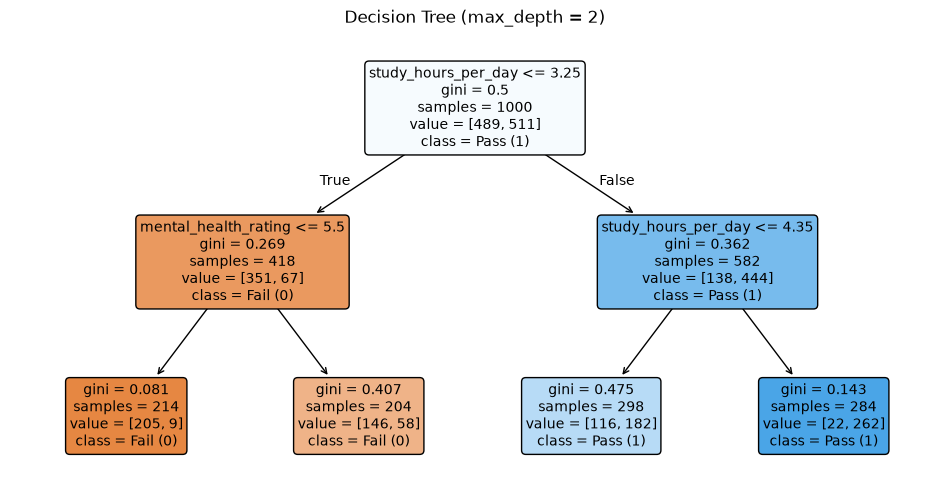

In [9]:
# Fit a shallow classification tree with max_depth=2
treeclf_shallow = DecisionTreeClassifier(max_depth=2, random_state=1)
treeclf_shallow.fit(X, y)

# Visualize the tree using matplotlib (no external system binaries required)
plt.figure(figsize=(12, 6))
plot_tree(
    treeclf_shallow, 
    feature_names=feature_cols, 
    class_names=['Fail (0)', 'Pass (1)'], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree (max_depth = 2)")
plt.show()

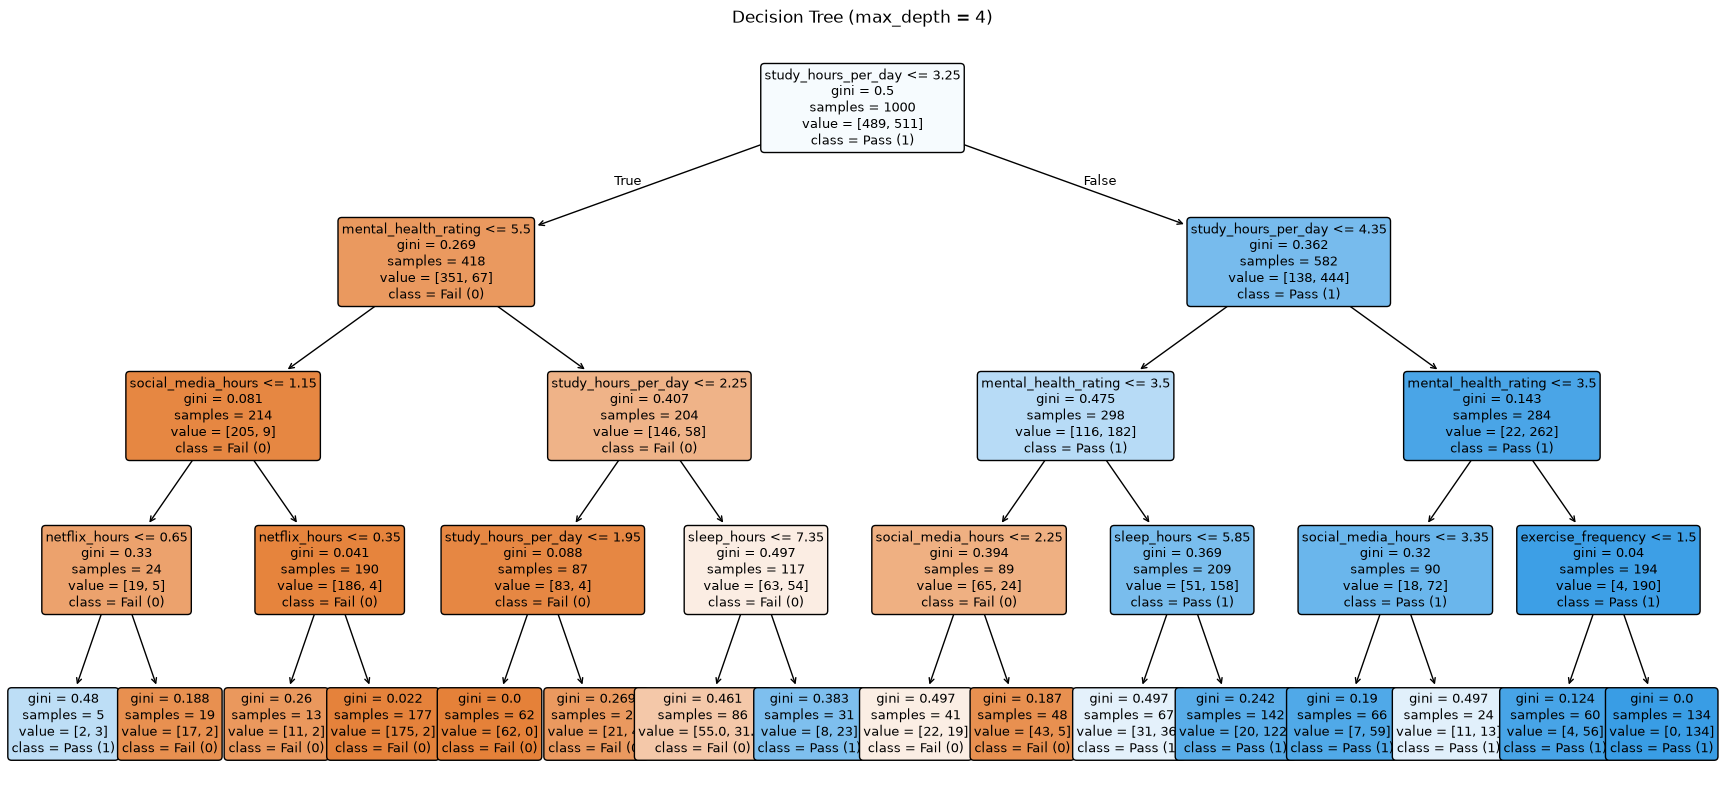

,feature,importance_depth_2,importance_depth_4
0,study_hours_per_day,0.943563,0.745477
6,mental_health_rating,0.056437,0.152840
4,sleep_hours,0.000000,0.053671
1,social_media_hours,0.000000,0.038662
2,netflix_hours,0.000000,0.008119
5,exercise_frequency,0.000000,0.001231
3,attendance_percentage,0.000000,0.000000
7,part_time_job_num,0.000000,0.000000
8,diet_quality_num,0.000000,0.000000


In [10]:
# Fit a deeper classification tree with max_depth=4
treeclf_deep = DecisionTreeClassifier(max_depth=4, random_state=1)
treeclf_deep.fit(X, y)

# Visualize the deeper tree
plt.figure(figsize=(22, 10))
plot_tree(
    treeclf_deep, 
    feature_names=feature_cols, 
    class_names=['Fail (0)', 'Pass (1)'], 
    filled=True, 
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree (max_depth = 4)")
plt.show()

# Compare Gini feature importances (professor's method)
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance_depth_2': treeclf_shallow.feature_importances_,
    'importance_depth_4': treeclf_deep.feature_importances_
}).sort_values(by='importance_depth_4', ascending=False)

display(importance_df)

In [13]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1)

# Standardize the features (fit only on training data, transform both)
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# Professor's function to draw the neural network (red = negative weight, blue = positive)
def show_ann(mlp):
    hidden_layers_n = len(mlp.coefs_) - 1
    layers_n = hidden_layers_n + 2
    input_neurons_n = len(mlp.coefs_[0])
    hidden_neurons_n = [len(mlp.coefs_[i+1]) for i in range(hidden_layers_n)]
    output_neurons_n = len(mlp.coefs_[-1][0])

    G = nx.DiGraph()
    pos = {}

    # Create the neurons of the input layer
    for i in range(input_neurons_n):
        pos['Layer0_{}'.format(i)] = (i, layers_n - 1)

    for j in range(hidden_layers_n):
        # Create the neurons of the j'th hidden layer
        prev_layer = j
        cur_layer = j + 1
        if (j == 0):
            prev_size = input_neurons_n
        else:
            prev_size = hidden_neurons_n[j - 1]
        for i in range(hidden_neurons_n[j]):
            pos['Layer{}_{}'.format(cur_layer, i)] = (i, layers_n - 1 - cur_layer)
            for k in range(prev_size):
                w = mlp.coefs_[prev_layer][k][i]
                G.add_edge('Layer{}_{}'.format(prev_layer, k), 'Layer{}_{}'.format(cur_layer, i), weight=w)

    # Create the neurons of the output layer
    prev_layer = hidden_layers_n
    cur_layer = hidden_layers_n + 1
    for i in range(output_neurons_n):
        pos['Layer{}_{}'.format(cur_layer, i)] = (i, layers_n - 1 - cur_layer)
        for k in range(hidden_neurons_n[-1]):
            w = mlp.coefs_[prev_layer][k][i]
            G.add_edge('Layer{}_{}'.format(prev_layer, k), 'Layer{}_{}'.format(cur_layer, i), weight=w)

    edges = G.edges()
    colors = [colorsys.hsv_to_rgb(0 if G[u][v]['weight'] < 0 else 0.65, 1, 1) for u, v in edges]
    weights = [abs(G[u][v]['weight']) * 2 for u, v in edges]

    nx.draw(G, pos, node_color='y', node_size=450, width=weights, edge_color=colors)

--- Architecture 1: (5,) ---
[[108  15]
 [ 11 116]]
              precision    recall  f1-score   support

           0       0.91      0.88      0.89       123
           1       0.89      0.91      0.90       127

    accuracy                           0.90       250
   macro avg       0.90      0.90      0.90       250
weighted avg       0.90      0.90      0.90       250



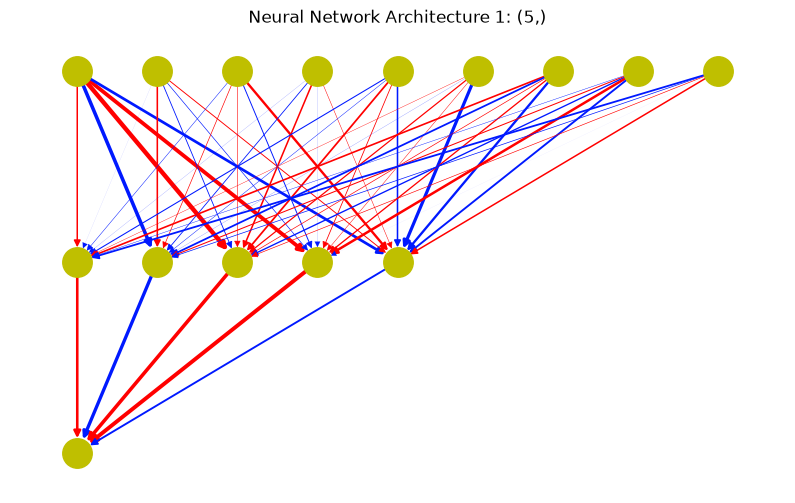

In [14]:
# Architecture 1: 1 hidden layer with 5 nodes
mlp1 = MLPClassifier(hidden_layer_sizes=(5,), max_iter=5000, random_state=1)
mlp1.fit(X_train, y_train)

predictions1 = mlp1.predict(X_test)
print("--- Architecture 1: (5,) ---")
print(confusion_matrix(y_test, predictions1))
print(classification_report(y_test, predictions1))

plt.figure(figsize=(10, 6))
plt.title("Neural Network Architecture 1: (5,)")
show_ann(mlp1)
plt.show()

--- Architecture 2: (9, 5) ---
[[112  11]
 [ 13 114]]
              precision    recall  f1-score   support

           0       0.90      0.91      0.90       123
           1       0.91      0.90      0.90       127

    accuracy                           0.90       250
   macro avg       0.90      0.90      0.90       250
weighted avg       0.90      0.90      0.90       250



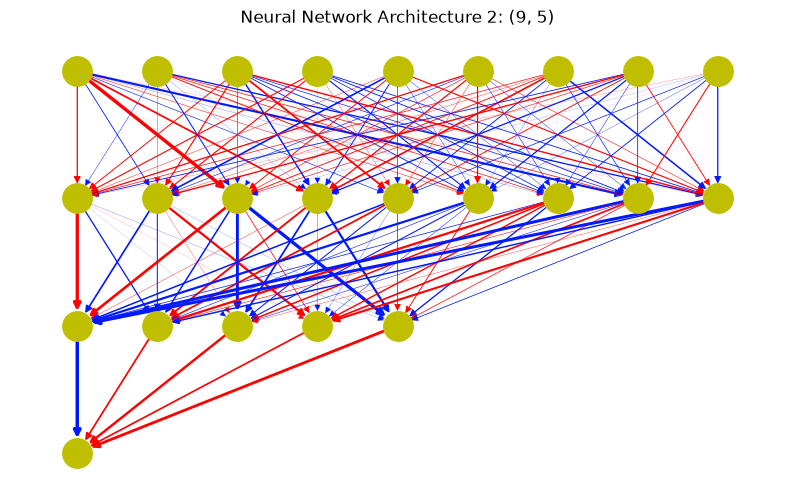

In [15]:
# Architecture 2: 2 hidden layers with 9 and 5 nodes
mlp2 = MLPClassifier(hidden_layer_sizes=(9, 5), max_iter=5000, random_state=1)
mlp2.fit(X_train, y_train)

predictions2 = mlp2.predict(X_test)
print("--- Architecture 2: (9, 5) ---")
print(confusion_matrix(y_test, predictions2))
print(classification_report(y_test, predictions2))

plt.figure(figsize=(10, 6))
plt.title("Neural Network Architecture 2: (9, 5)")
show_ann(mlp2)
plt.show()

--- Architecture 3: (12, 8, 4) ---
[[109  14]
 [ 13 114]]
              precision    recall  f1-score   support

           0       0.89      0.89      0.89       123
           1       0.89      0.90      0.89       127

    accuracy                           0.89       250
   macro avg       0.89      0.89      0.89       250
weighted avg       0.89      0.89      0.89       250



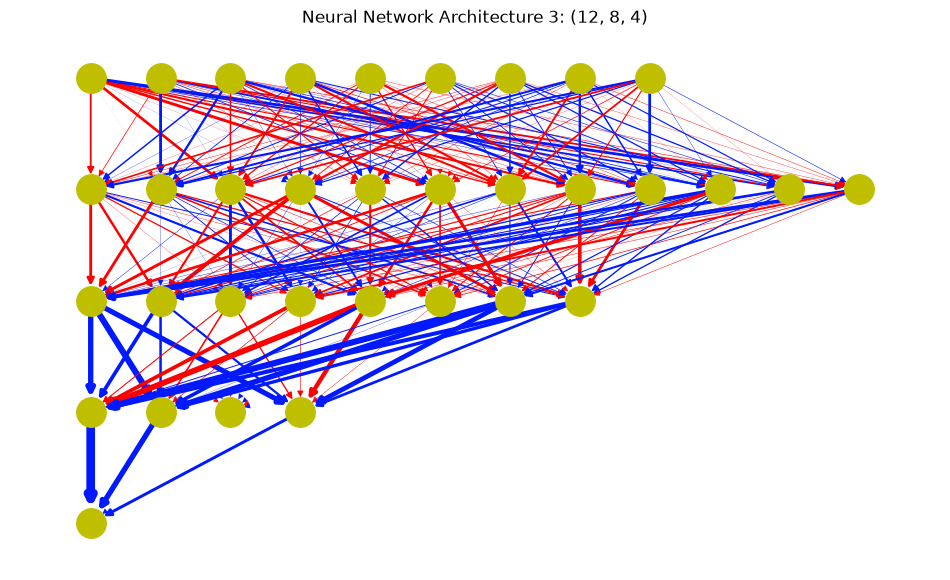

In [16]:
# Architecture 3: 3 hidden layers with 12, 8, and 4 nodes
mlp3 = MLPClassifier(hidden_layer_sizes=(12, 8, 4), max_iter=5000, random_state=1)
mlp3.fit(X_train, y_train)

predictions3 = mlp3.predict(X_test)
print("--- Architecture 3: (12, 8, 4) ---")
print(confusion_matrix(y_test, predictions3))
print(classification_report(y_test, predictions3))

plt.figure(figsize=(12, 7))
plt.title("Neural Network Architecture 3: (12, 8, 4)")
show_ann(mlp3)
plt.show()

In [17]:
# Calculate the average absolute edge weight leaving each input node (Layer 0 -> Layer 1)
comparison_df = pd.DataFrame({
    'input_node': [f'Layer0_{i}' for i in range(len(feature_cols))],
    'feature': feature_cols,
    'tree_depth_2_gini': treeclf_shallow.feature_importances_,
    'tree_depth_4_gini': treeclf_deep.feature_importances_,
    'nn1_mean_abs_weight': np.mean(np.abs(mlp1.coefs_[0]), axis=1),
    'nn2_mean_abs_weight': np.mean(np.abs(mlp2.coefs_[0]), axis=1),
    'nn3_mean_abs_weight': np.mean(np.abs(mlp3.coefs_[0]), axis=1)
}).sort_values(by='tree_depth_4_gini', ascending=False)

display(comparison_df)

,input_node,feature,tree_depth_2_gini,tree_depth_4_gini,nn1_mean_abs_weight,nn2_mean_abs_weight,nn3_mean_abs_weight
0,Layer0_0,study_hours_per_day,0.943563,0.745477,1.152947,0.429352,0.524810
6,Layer0_6,mental_health_rating,0.056437,0.152840,0.552051,0.277601,0.331424
4,Layer0_4,sleep_hours,0.000000,0.053671,0.404423,0.262715,0.254049
1,Layer0_1,social_media_hours,0.000000,0.038662,0.290621,0.229093,0.331441
2,Layer0_2,netflix_hours,0.000000,0.008119,0.362504,0.381050,0.409309
5,Layer0_5,exercise_frequency,0.000000,0.001231,0.387888,0.272185,0.276509
3,Layer0_3,attendance_percentage,0.000000,0.000000,0.224162,0.249492,0.359465
7,Layer0_7,part_time_job_num,0.000000,0.000000,0.516605,0.326642,0.359527
8,Layer0_8,diet_quality_num,0.000000,0.000000,0.335285,0.184198,0.422310
